# Segment stencils: fitting and reading

This notebook walks through how a per-segment **stencil** is fitted to a
display, and how `SegmentReader` uses it to decide which segments are lit.

1. Load the session data
2. Activity (std) and mean images
3. Fit a stencil step by step
4. Inspect the segment masks
5. Read one frame with `SegmentReader`
6. Calibrate the lit threshold
7. Read every session, with a cross-check (displays 00 and 04 show the same meter)
8. Known edge cases
9. Accuracy against hand-checked labels

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from seven_segment.fit_stencils import (
    LAYOUT,
    activity,
    fit_dp,
    initial_guess,
    refine,
    refine_offsets,
    score,
)
from seven_segment.segments import (
    SegmentReader,
    calibrate_threshold,
    evaluate,
    load_labels,
    read_all,
    save_readings_csv,
    save_segments_csv,
)
from seven_segment.sessions import SessionLoader
from seven_segment.stencils import DisplayStencil, overlay

# Find the repository root so the notebook works from any working directory.
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
loader = SessionLoader(ROOT / "data" / "sessions")
plt.rcParams["figure.dpi"] = 110
print(f"{len(loader)} sessions, {len(loader[0])} displays each")

64 sessions, 10 displays each


## 1. Session data

A session is one capture of all 10 displays. Displays have different sizes,
so a session is a *list* of 2-D `uint8` arrays rather than a single array.

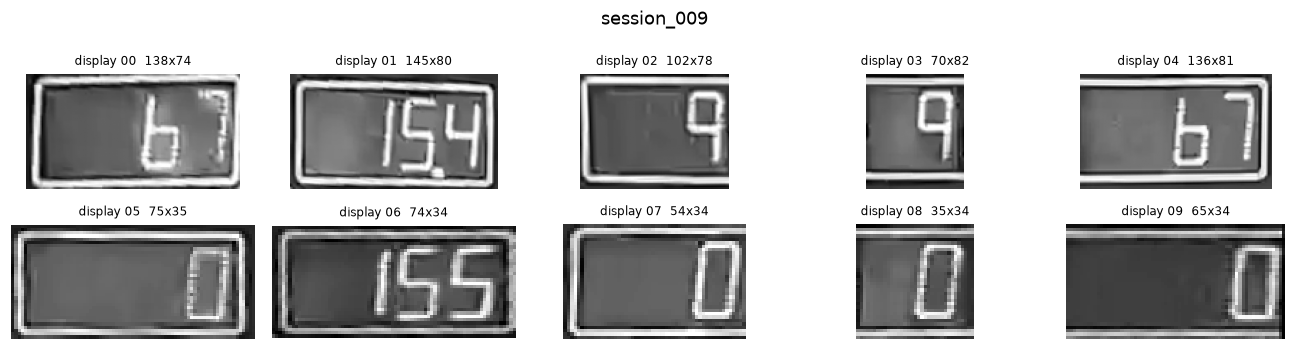

In [2]:
session = loader[8]
fig, axes = plt.subplots(2, 5, figsize=(12, 3.2))
for i, (ax, img) in enumerate(zip(axes.flat, session)):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"display {i:02d}  {img.shape[1]}x{img.shape[0]}", fontsize=8)
    ax.axis("off")
fig.suptitle("session_009")
plt.tight_layout()

## 2. Activity and mean images

Stacking one display across all sessions:

* **mean**: the bezel plus a faint ghost of every segment that was ever lit;
* **activity** (per-pixel std): bright where pixels switch on and off, which
  makes the segments stand out from the static background.

Segments that never change (e.g. the left digit of display 00 only ever
shows "1" or "2") are invisible in the activity image. That's why the
stencil is a *geometric template* fitted to the data, not a thresholded image.

stack shape (sessions, H, W): (64, 80, 145)


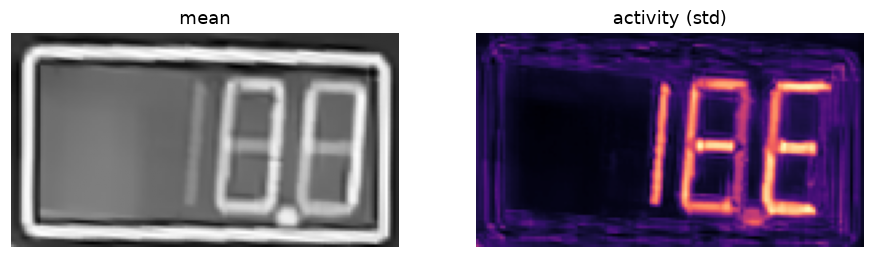

In [3]:
DISPLAY = 1  # shows readings like "15.4": 3 digits, decimal point after digit 1
stack = np.stack([s[DISPLAY] for s in loader])
act = activity(stack)
mean = stack.astype(np.float32).mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].imshow(mean, cmap="gray")
axes[0].set_title("mean")
axes[1].imshow(act, cmap="magma")
axes[1].set_title("activity (std)")
for ax in axes:
    ax.axis("off")
print("stack shape (sessions, H, W):", stack.shape)

## 3. Fitting a stencil step by step

`fit_display` chains these steps; here they run one at a time.

1. `initial_guess`: bounding box of high-activity pixels, anchored on the
   right-most digit (which always changes), plus typical digit proportions.
2. `refine`: coordinate descent over `x0, y0, w, h, pitch, slant, stroke` to
   maximise activity under the segment masks minus activity inside the digit
   holes (the `score`).
3. `refine_offsets`: a small horizontal shift per digit for uneven spacing.
4. `fit_dp`: the decimal point is placed on the most active spot in a window
   below the gap between two digits. Spots overlapping a segment are
   excluded, otherwise the search picks the (also active) end of segment c/d.

Green: segments, blue: holes (local background), red: decimal point.

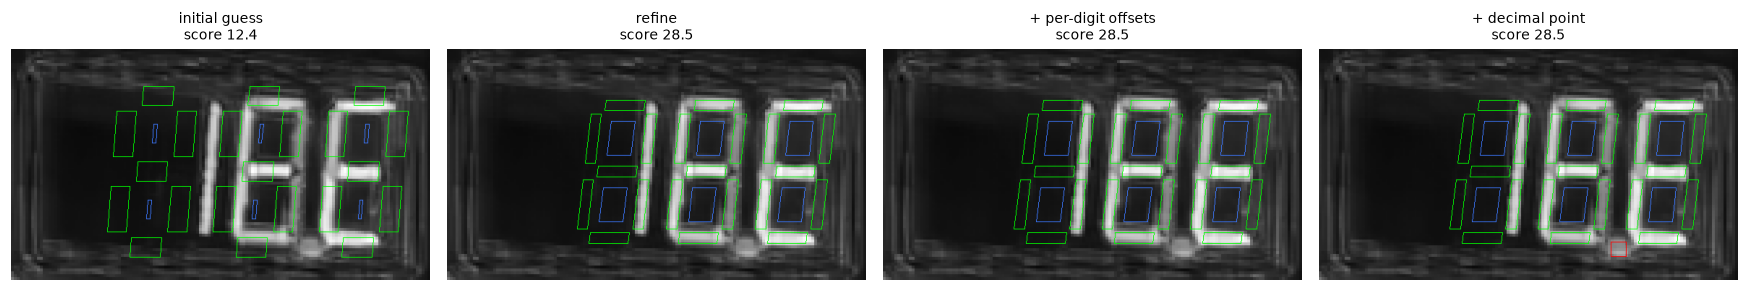

In [4]:
n_digits, dps = LAYOUT[DISPLAY]
act_u8 = (255 * act / act.max()).astype(np.uint8)

s0 = initial_guess(act, n_digits)
s1 = refine(s0, act)
s2 = refine_offsets(s1, act)
s3 = replace(s2, dp={d: fit_dp(s2, act, d) for d in dps})

steps = [
    ("initial guess", s0),
    ("refine", s1),
    ("+ per-digit offsets", s2),
    ("+ decimal point", s3),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (name, st) in zip(axes, steps):
    ax.imshow(overlay(act_u8, st, scale=4))
    ax.axis("off")
    ax.set_title(f"{name}\nscore {score(st, act):.1f}", fontsize=9)
plt.tight_layout()

The result is saved as JSON in `stencils/`. These files are small,
human-editable annotations: if an overlay looks off, edit the numbers and
redraw with `python -m seven_segment.fit_stencils data/sessions --overlay-only`.

In [5]:
stencil = DisplayStencil.load(ROOT / "stencils" / f"display_{DISPLAY:02d}.json")
print(stencil.to_json())

{
  "width": 145,
  "height": 80,
  "n_digits": 3,
  "x0": 44.435,
  "y0": 17.75,
  "w": 22.935,
  "h": 49.5,
  "pitch": 30.83,
  "slant": 0.11999999999999997,
  "stroke": 3.6805555555555554,
  "dp": {
    "1": [
      103.74861111111112,
      69.38888888888889
    ]
  },
  "dx": [
    0.47916666666666696,
    -0.020833333333333037,
    -0.27083333333333304
  ],
  "threshold": 40.4
}


## 4. Segment masks

`segment_masks()` returns one soft mask (weights 0..1) per segment, keyed
`"<digit>.<segment>"`. Every segment gets a mask, including ones that never
lit in the data, and the masks don't overlap (corners are left out).

22 masks: ['0.a', '0.b', '0.c', '0.d', '0.e', '0.f', '0.g', '1.a', '1.b', '1.c', '1.d', '1.e', '1.f', '1.g', '1.dp', '2.a', '2.b', '2.c', '2.d', '2.e', '2.f', '2.g']


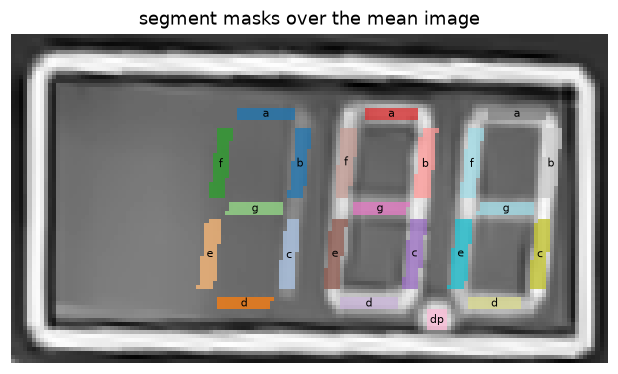

In [6]:
masks = stencil.segment_masks()
print(len(masks), "masks:", list(masks))

label = np.zeros(stack.shape[1:], dtype=float)
for k, m in enumerate(masks.values(), start=1):
    label = np.where(m > 0.5, k, label)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(mean, cmap="gray")
ax.imshow(
    np.ma.masked_equal(label, 0), cmap="tab20", alpha=0.75, interpolation="nearest"
)
for name, m in masks.items():
    ys, xs = np.nonzero(m > 0.5)
    ax.text(
        xs.mean(), ys.mean(), name.split(".")[1], ha="center", va="center", fontsize=7
    )
ax.set_title("segment masks over the mean image")
ax.axis("off");

## 5. Reading a frame with `SegmentReader`

The feature for each segment is its mean brightness **minus** the mean of its
digit's holes. Frames are contrast-stretched one by one, so absolute brightness
isn't comparable between frames, but this difference is: unlit segments sit
near 0, lit ones well above. A segment is lit if its feature exceeds the
display's calibrated `threshold`.

reading: 15.4
lit segments: ['0.b', '0.c', '1.a', '1.c', '1.d', '1.f', '1.g', '1.dp', '2.b', '2.c', '2.f', '2.g']


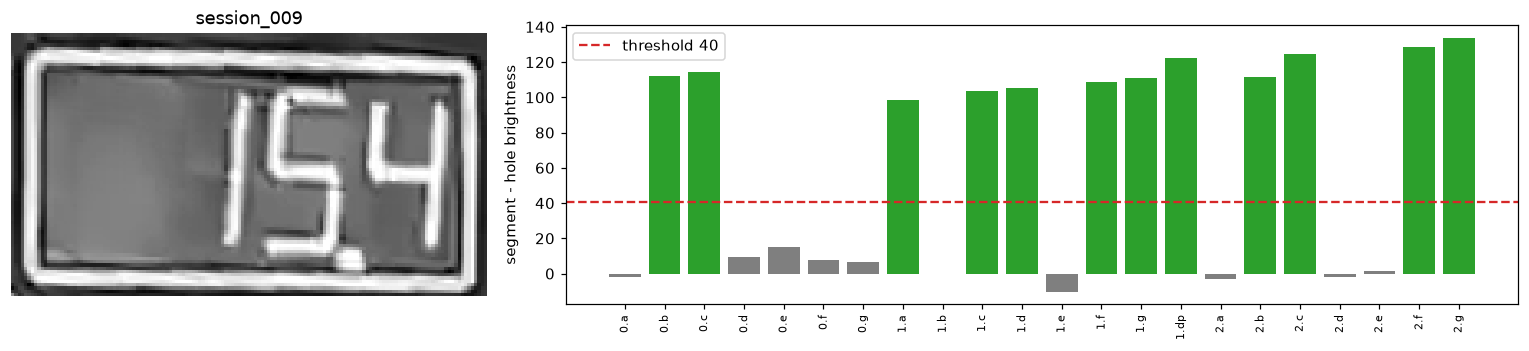

In [7]:
reader = SegmentReader(stencil)
img = loader[8][DISPLAY]

feats = reader.features(img)
lit = reader.lit(img)
print("reading:", reader.read(img))
print("lit segments:", [n for n, on in lit.items() if on])

fig, (ax0, ax1) = plt.subplots(
    1, 2, figsize=(14, 3.2), gridspec_kw={"width_ratios": [1, 2]}
)
ax0.imshow(img, cmap="gray")
ax0.axis("off")
ax0.set_title("session_009")
ax1.bar(
    reader.names,
    feats,
    color=["tab:green" if lit[n] else "tab:gray" for n in reader.names],
)
ax1.axhline(
    stencil.threshold,
    color="tab:red",
    ls="--",
    label=f"threshold {stencil.threshold:.0f}",
)
ax1.set_ylabel("segment - hole brightness")
ax1.legend()
ax1.tick_params(axis="x", labelsize=7, rotation=90)
plt.tight_layout()

## 6. Calibrating the threshold

`calibrate_threshold` pools the features of all segments over all sessions.
Otsu's method splits them into an unlit and a lit cluster, and the threshold
is put 35 % of the way from the unlit median to the lit median. Otsu's own
split sits too high because lit brightness varies a lot between segments.

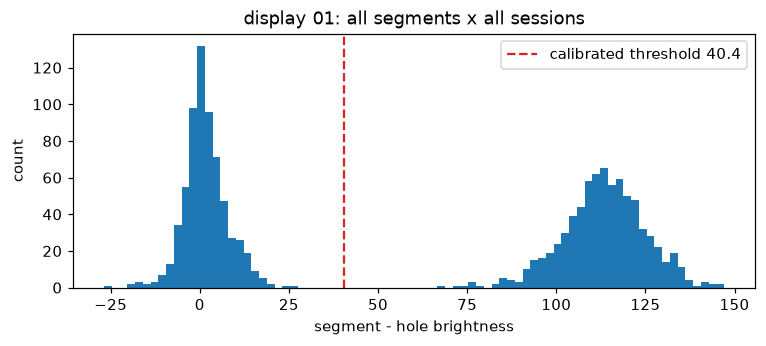

In [8]:
all_feats = np.stack([reader.features(s[DISPLAY]) for s in loader])
t = calibrate_threshold(all_feats)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(all_feats.ravel(), bins=80, color="tab:blue")
ax.axvline(t, color="tab:red", ls="--", label=f"calibrated threshold {t:.1f}")
ax.set_xlabel("segment - hole brightness")
ax.set_ylabel("count")
ax.legend()
ax.set_title(f"display {DISPLAY:02d}: all segments x all sessions");

## 7. Reading every display in every session

`read_all` calibrates each display and decodes all sessions. Unknown segment
patterns decode to `?`. Displays **00** and **04** are two views of the same
meter, which gives an independent check of the whole pipeline.

The results are saved to `outputs/readings/`:

* `readings.csv`: one row per session, one column per display;
* `segments.csv`: every segment decision (session, display, segment,
  feature, threshold, lit), for analysing *why* a reading came out as it did.

The same files are written by `uv run python -m seven_segment.segments data/sessions`.

In [9]:
stencils = [
    DisplayStencil.load(p) for p in sorted((ROOT / "stencils").glob("display_*.json"))
]
readings, thresholds = read_all(loader, stencils)

# Full table: all sessions, all displays. "?" = unknown segment pattern.
print("session " + " ".join(f"{i:>6}" for i in range(len(stencils))))
for k, row in enumerate(readings, start=1):
    print(f"{k:>7} " + " ".join(f"{r:>6}" for r in row))

flat = [r for row in readings for r in row]
agree = sum(row[0] == row[4] for row in readings)
print(f"\ninvalid readings: {sum('?' in r for r in flat)} / {len(flat)}")
print(f"display 00 == display 04 in {agree} / {len(readings)} sessions")

session      0      1      2      3      4      5      6      7      8      9
      1      0    1.4      0      0      0      0   20.0      0      0      0
      2      0    1.4      0      0      0      0   20.0      0      0      0
      3      0   19.4      0      0      0      0    195      0      0      0
      4      0   18.8      0      0      0      0    189      0      0      0
      5     12   18.1      2      6     12      0    182      0      0      0
      6     21   17.4      3      9     21      0    175      0      0      0
      7     35   16.8      5      7     35      0    169      0      0      0
      8     51   16.1      7      8     51      0    162      0      0      0
      9     67   15.4      9      9     67      0    155      0      0      0
     10     80   14.8     11      8     80      0    149      0      0      0
     11     93    141     13      7     93      0    142      0      0      0
     12    103   13.4     15      4    103      0    135      0 

In [10]:
out_dir = ROOT / "outputs" / "readings"
save_readings_csv(out_dir / "readings.csv", readings)
save_segments_csv(out_dir / "segments.csv", loader, stencils, thresholds)

for name in ("readings.csv", "segments.csv"):
    lines = (out_dir / name).read_text().splitlines()
    print(f"{(out_dir / name).relative_to(ROOT)}: {len(lines) - 1} rows")
    print("  " + "\n  ".join(lines[:4]), "\n")

outputs/readings/readings.csv: 64 rows
  session,display_00,display_01,display_02,display_03,display_04,display_05,display_06,display_07,display_08,display_09
  1,0,1.4,0,0,0,0,20.0,0,0,0
  2,0,1.4,0,0,0,0,20.0,0,0,0
  3,0,19.4,0,0,0,0,195,0,0,0 

outputs/readings/segments.csv: 10880 rows
  session,display,segment,feature,threshold,lit
  1,0,0.a,-11.70,31.03,0
  1,0,0.b,0.67,31.03,0
  1,0,0.c,2.62,31.03,0 



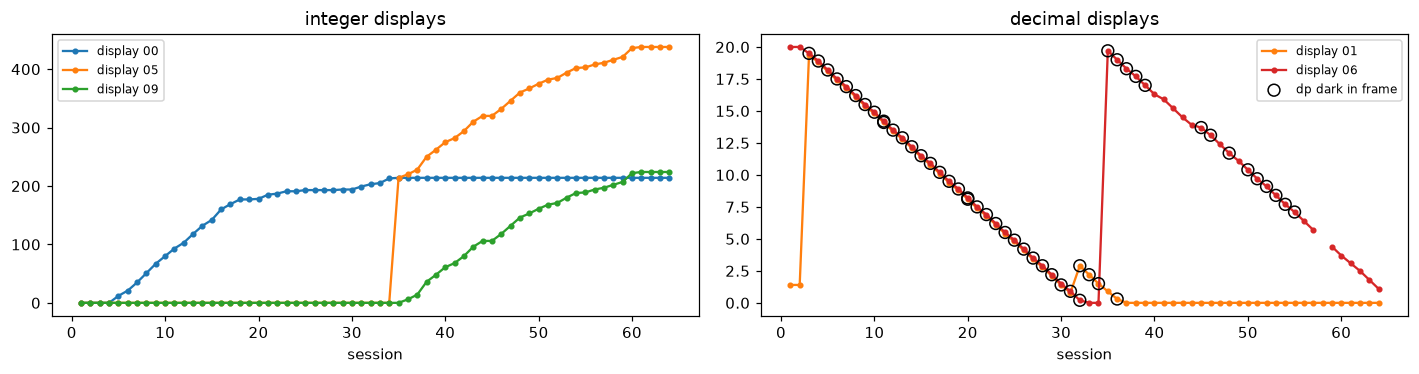

In [11]:
def as_number(text):
    try:
        return float(text)
    except ValueError:
        return np.nan


sessions = np.arange(1, len(readings) + 1)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 3.5))
for i in (0, 5, 9):
    ax0.plot(
        sessions,
        [as_number(row[i]) for row in readings],
        marker=".",
        label=f"display {i:02d}",
    )
ax0.set_title("integer displays")
ax0.set_xlabel("session")
ax0.legend(fontsize=8)

# Displays 01 and 06 always show one decimal. Frames where the dp was dark
# decode without it ("141"); plot those at value/10 with a hollow marker.
for i, colour in ((1, "tab:orange"), (6, "tab:red")):
    vals = np.array([as_number(row[i]) for row in readings])
    no_dp = np.array(["." not in row[i] and "?" not in row[i] for row in readings])
    fixed = np.where(no_dp, vals / 10, vals)
    ax1.plot(sessions, fixed, marker=".", color=colour, label=f"display {i:02d}")
    ax1.scatter(
        sessions[no_dp], fixed[no_dp], s=60, facecolors="none", edgecolors="k", zorder=3
    )
ax1.scatter([], [], s=60, facecolors="none", edgecolors="k", label="dp dark in frame")
ax1.set_title("decimal displays")
ax1.set_xlabel("session")
ax1.legend(fontsize=8)
plt.tight_layout()

## 8. Known edge cases

* **Mid-change frames:** display 06, session 58 caught the display switching
  to "5.0". Two segments of the last digit are half faded, so it decodes to
  `?`. A mid-change frame can also decode to a *valid but wrong* digit
  without a warning.
* **Dark decimal point:** on displays 01 and 06 the dp is genuinely dark in
  some frames (e.g. display 01, session 11 reads "141" for 14.1), probably
  because the camera caught the display mid-refresh. The reader reports what
  the image shows.

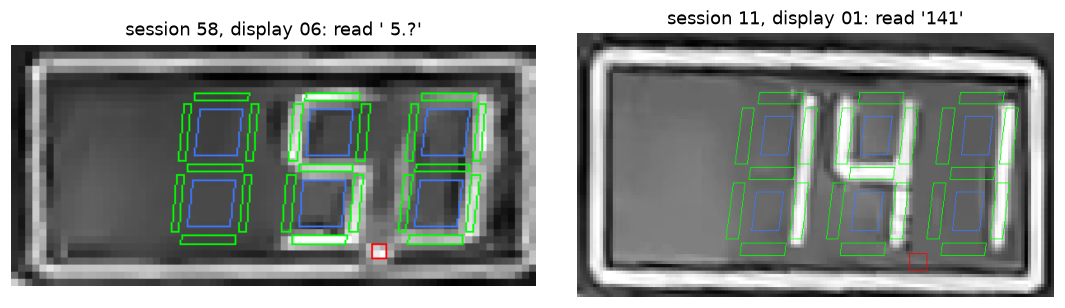

In [12]:
cases = [(58, 6), (11, 1)]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, (k, d) in zip(axes, cases):
    r = SegmentReader(stencils[d])
    img = loader[k - 1][d]
    ax.imshow(overlay(img, stencils[d], scale=4))
    ax.axis("off")
    ax.set_title(f"session {k}, display {d:02d}: read {r.read(img)!r}")
plt.tight_layout()

## 9. Accuracy against hand-checked labels

`labels/readings.csv` holds readings checked by hand in the review app
(`uv run python -m seven_segment.review_app`). Comparing them with the
reader's output gives its real accuracy.

Caveat: the thresholds were calibrated on these same 64 sessions, so this
is in-sample accuracy. New recordings may do worse.

Each mismatch is put into one category:

* **decimal point:** only the dot differs (e.g. `19.5` vs `195`);
* **invalid:** the reader flagged an unknown segment pattern (`?`);
* **digit:** at least one digit differs;
* **uncertain label:** you marked the label itself with `?`.

In [13]:
labels = load_labels(ROOT / "labels" / "readings.csv")
if not labels:
    raise SystemExit("No labels yet: check some readings in the review app first.")

scores = evaluate(readings, labels)  # display -> (correct, checked)
ok = sum(c for c, _ in scores.values())
n = sum(t for _, t in scores.values())
print(f"overall: {ok}/{n} correct = {100 * ok / n:.1f} %\n")
print("display  correct/checked  accuracy")
for d, (c, t) in scores.items():
    print(f"     {d:02d}  {c:>7}/{t:<7}  {100 * c / t:6.1f} %")

overall: 633/640 correct = 98.9 %

display  correct/checked  accuracy
     00       64/64        100.0 %
     01       64/64        100.0 %
     02       64/64        100.0 %
     03       64/64        100.0 %
     04       64/64        100.0 %
     05       64/64        100.0 %
     06       57/64         89.1 %
     07       64/64        100.0 %
     08       64/64        100.0 %
     09       64/64        100.0 %


In [14]:
def error_kind(predicted: str, label: str) -> str:
    if "?" in label:
        return "uncertain label"
    if "?" in predicted:
        return "invalid"
    if predicted.replace(".", "") == label.replace(".", ""):
        return "decimal point"
    return "digit"


# (session, display, predicted, label, kind) for every disagreement.
mismatches = [
    (k, d, readings[k - 1][d].strip(), lab, error_kind(readings[k - 1][d].strip(), lab))
    for (k, d), lab in sorted(labels.items())
    if readings[k - 1][d].strip() != lab
]
kinds = ["decimal point", "invalid", "digit", "uncertain label"]
counts = {kind: sum(m[4] == kind for m in mismatches) for kind in kinds}
print(
    f"{len(mismatches)} mismatches:", ", ".join(f"{v} {k}" for k, v in counts.items())
)
print()
print("session display  reader   label    kind")
for k, d, pred, lab, kind in mismatches:
    print(f"{k:>7} {d:>7}  {pred:<7}  {lab:<7}  {kind}")

7 mismatches: 5 decimal point, 1 invalid, 0 digit, 1 uncertain label

session display  reader   label    kind
      5       6  182      18.2     decimal point
     23       6  62       6?2      uncertain label
     31       6  09       0.9      decimal point
     32       6  02       0.2      decimal point
     37       6  183      18.3     decimal point
     58       6  5.?      5.0      invalid
     62       6  2.5      25       decimal point


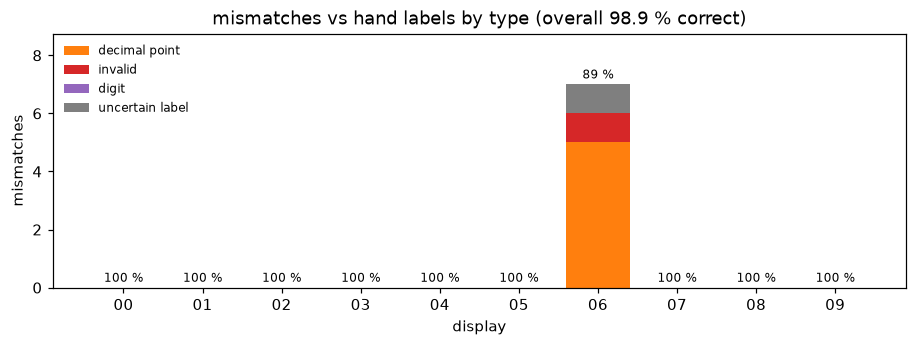

In [15]:
# Errors only: with ~99 % correct, a bar of all readings would hide them.
displays = list(scores)
x = np.arange(len(displays))
fig, ax = plt.subplots(figsize=(10, 3))
bottom = np.zeros(len(displays))
for kind, colour in zip(kinds, ["tab:orange", "tab:red", "tab:purple", "tab:gray"]):
    vals = np.array(
        [sum(m[1] == d and m[4] == kind for m in mismatches) for d in displays]
    )
    ax.bar(x, vals, bottom=bottom, color=colour, label=kind)
    bottom += vals
for xi, d in enumerate(displays):
    c, t = scores[d]
    ax.text(
        xi,
        bottom[xi] + 0.1,
        f"{100 * c / t:.0f} %",
        ha="center",
        va="bottom",
        fontsize=8,
    )
ax.set_xticks(x, [f"{d:02d}" for d in displays])
ax.set_ylim(0, max(bottom.max() * 1.25, 1))
ax.set_xlabel("display")
ax.set_ylabel("mismatches")
ax.set_title(
    f"mismatches vs hand labels by type (overall {100 * ok / n:.1f} % correct)"
)
ax.legend(loc="upper left", fontsize=8, frameon=False);

Every mismatch with its image. Left: the original with the stencil
(green = lit segment, red outline = unlit); the title gives the reader's
output and your label. Some may be labelling slips: compare with the image
and fix them in the review app if needed.

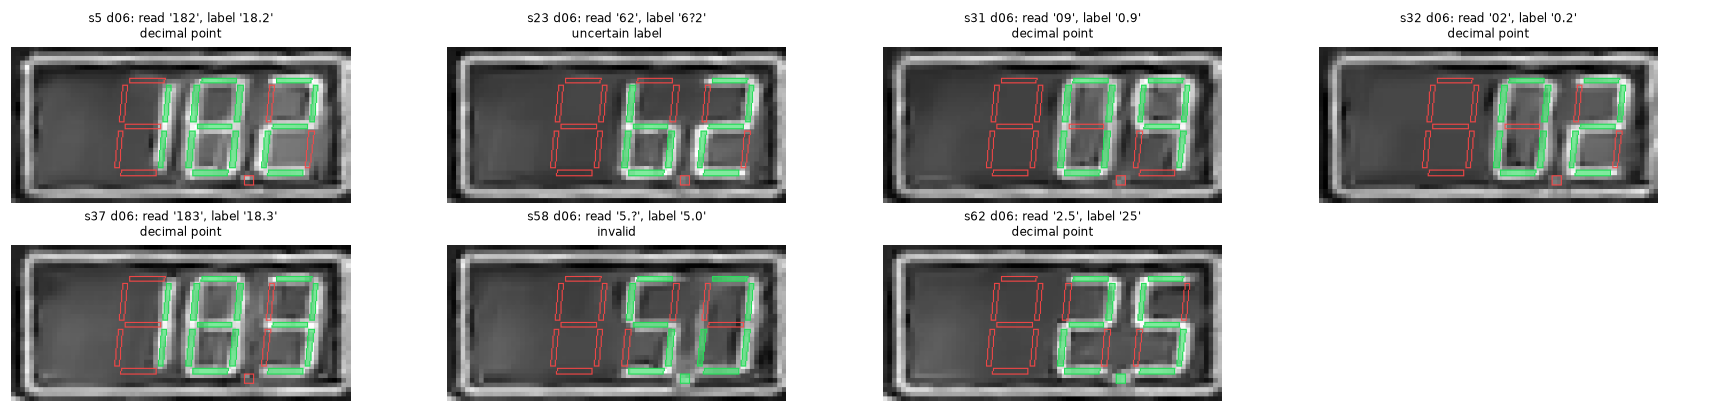

In [16]:
if mismatches:
    cols = 4
    rows = -(-len(mismatches) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 1.9 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (k, d, pred, lab, kind) in zip(axes.flat, mismatches):
        img = loader[k - 1][d]
        lit = SegmentReader(stencils[d]).lit(img, thresholds[d])
        ax.imshow(overlay(img, stencils[d], scale=4, lit=lit))
        ax.set_title(f"s{k} d{d:02d}: read {pred!r}, label {lab!r}\n{kind}", fontsize=8)
    plt.tight_layout()
else:
    print("No mismatches.")